In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.ndimage import gaussian_filter
import ast
import re
from sklearn.cluster import KMeans


In [4]:
final_2025_formations = pd.read_csv('final_2025_formations.csv')
final_2025_formations

,Unnamed: 0,game_id,gsis_play_id,x_ball_at_snap,y_ball_at_snap,all_player_locations,team_abbr,qb_x,qb_y,left_wr_label,...,ol_left_edge,ol_right_edge,backfield_count,backfield_locations,backfield_ids,backfield_outside_tackles,qb_alignment,formation_strength,backfield_in_motion,backset_formation
0,0,2025090400,71,56.23,23.87,"[('QB', (np.float64(0.91), np.float64(0.24))),...",DAL,0.91,0.24,Slot,...,-3.22,3.08,2,"[(6.91, 0.29), (2.25, 1.08)]","[(53464,), (54594,)]",True,UNDER_CENTER,positive,True,I Strong with skill position in motion
1,1,2025090400,112,63.49,30.07,"[('QB', (np.float64(3.66), np.float64(0.18))),...",DAL,3.66,0.18,Toad Wing,...,-3.20,3.14,1,"[(4.27, 2.77)]","[(53464,)]",True,SHOTGUN,negative,True,Shotgun Weak with skill position in motion
2,2,2025090400,141,67.39,23.92,"[('QB', (np.float64(3.47), np.float64(0.28))),...",DAL,3.47,0.28,Trips,...,-3.06,3.21,1,"[(3.45, -2.16)]","[(56457,)]",True,SHOTGUN,negative,True,Shotgun Strong with skill position in motion
3,3,2025090400,166,72.96,23.96,"[('QB', (np.float64(1.01), np.float64(0.27))),...",DAL,1.01,0.27,Trey,...,-3.51,3.40,2,"[(2.91, 0.38), (6.51, 0.31)]","[(53117,), (53464,)]",True,UNDER_CENTER,negative,True,I with skill position in motion
4,4,2025090400,188,76.92,24.22,"[('QB', (np.float64(1.0), np.float64(0.2))), (...",DAL,1.00,0.20,Open,...,-3.35,3.07,1,"[(6.77, 0.14)]","[(53464,)]",True,UNDER_CENTER,positive,False,Ace
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32783,33304,2026010413,3887,83.24,29.97,"[('QB', (np.float64(4.42), np.float64(0.2))), ...",PIT,4.42,0.20,Open,...,-3.05,3.12,1,"[(4.56, -1.89)]","[(53579,)]",True,SHOTGUN,positive,True,Shotgun Weak with skill position in motion
32784,33305,2026010413,3956,63.33,29.95,"[('QB', (np.float64(-4.85), np.float64(0.17)))...",BAL,-4.85,0.17,Slot,...,3.40,-3.33,1,"[(-4.44, -2.01)]","[(43334,)]",True,SHOTGUN,negative,True,Shotgun Strong with skill position in motion
32785,33306,2026010413,4027,60.39,24.02,"[('QB', (np.float64(-5.02), np.float64(0.23)))...",BAL,-5.02,0.23,Slot,...,3.65,-3.21,2,"[(-4.8, 2.55), (-3.16, -1.88)]","[(43334,), (54604,)]",True,SHOTGUN,negative,True,Shotgun Split Weak with skill position in motion
32786,33307,2026010413,4050,60.50,23.88,"[('QB', (np.float64(-4.76), np.float64(0.04)))...",BAL,-4.76,0.04,Open,...,3.48,-3.36,1,"[(-4.56, -2.22)]","[(43334,)]",True,SHOTGUN,negative,False,Shotgun Strong


In [ ]:
def parse_player_locations(val):
    if isinstance(val, str):
        cleaned = re.sub(r'np\.float64\(([^)]+)\)', r'\1', val)
        return ast.literal_eval(cleaned)
    return val

In [5]:
def get_formation_key(row):
    """A formation = backfield alignment/description + which receiver label sits on each side."""
    return (row['backset_formation'], row['left_wr_label'], row['right_wr_label'])

In [137]:
def get_top_formations(df, game_id, team_col='possession_team', team=None, top_n=3):

    game_df = df[df['game_id'] == game_id].copy()
    if team is not None:
        game_df = game_df[game_df[team_col] == team].copy()
        # print('here')

    game_df['formation_key'] = game_df.apply(get_formation_key, axis=1)
    counts = game_df['formation_key'].value_counts()
    top_keys = counts.head(top_n).index.tolist()

    return [
        (key, counts[key], game_df[game_df['formation_key'] == key])
        for key in top_keys
    ]

In [134]:
def extract_direction_corrected_points(play_rows):
    all_points = []

    for _, row in play_rows.iterrows():
        locations = parse_player_locations(row['all_player_locations'])
        # print(locations)

        qb_depth = next((coords[0] for label, coords in locations if label == 'QB'), None)
        direction_mult = 1 if (qb_depth is None or qb_depth >= 0) else -1

        for label, coords in locations:
            x, y = coords
            px = y
            py = -direction_mult * x
            all_points.append((label, px, py))

    return pd.DataFrame(all_points, columns=['label', 'px', 'py'])


In [166]:
def allocate_remaining_slots(counts, total_slots, base_allocation):
    remaining = total_slots - sum(base_allocation.values())
    if remaining <= 0:
        return base_allocation

    total_count = sum(counts.values())
    if total_count == 0:
        return base_allocation

    raw = {k: remaining * counts[k] / total_count for k in counts}
    floor_alloc = {k: int(np.floor(v)) for k, v in raw.items()}
    leftover = remaining - sum(floor_alloc.values())

    # give leftover slots to the groups with the largest fractional remainder
    remainders = sorted(raw.keys(), key=lambda k: raw[k] - floor_alloc[k], reverse=True)
    for k in remainders[:leftover]:
        floor_alloc[k] += 1

    final = dict(base_allocation)
    for k in floor_alloc:
        final[k] = final.get(k, 0) + floor_alloc[k]
    # print(final)
    return final


def get_position_dots(points_df):
    """Returns a list of (label, x, y) dots: 1 QB, 5 OL, and 5 skill-position dots
    (guaranteeing at least 1 each of RB, WR, TE when present in the data)."""
    dots = []

    # QB — single dot
    qb_df = points_df[points_df['label'] == 'QB']
    if len(qb_df) > 0:
        dots.append(('QB', qb_df['px'].median(), qb_df['py'].median()))

    # OL — 5 dots via clustering
    ol_df = points_df[points_df['label'] == 'OL']
    if len(ol_df) >= 5:
        km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(ol_df[['px', 'py']])
        centers = km.cluster_centers_[np.argsort(km.cluster_centers_[:, 0])]  # left-to-right order
        for cx, cy in centers:
            dots.append(('OL', cx, cy))
    elif len(ol_df) > 0:
        for _, r in ol_df.iterrows():
            dots.append(('OL', r['px'], r['py']))

    # Skill positions — 5 total, minimum 1 each of RB, WR, TE (when present)
    skill_groups = {
        'RB': points_df[points_df['label'].isin(['RB', 'FB'])],
        'WR': points_df[points_df['label'] == 'WR'],
        'TE': points_df[points_df['label'] == 'TE'],
    }
    available = {k: v for k, v in skill_groups.items() if len(v) > 0}

    base_allocation = {k: 1 for k in available}
    counts = {k: len(v) for k, v in available.items()}
    # print(counts)
    allocation = allocate_remaining_slots(counts, total_slots=5, base_allocation=base_allocation)

    for label, df_sub in available.items():
        k = allocation.get(label, 0)
        if k <= 0:
            continue
        if len(df_sub) >= k:
            km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(df_sub[['px', 'py']])
            centers = km.cluster_centers_
        else:
            centers = df_sub[['px', 'py']].values  # fewer raw points than requested slots
        for cx, cy in centers:
            dots.append((label, cx, cy))

    return dots

In [126]:
def formation_heatmap(play_rows, team, formation_label, bins=150, sigma=5,
                       xlim=(-30, 30), ylim=(-10, 15)):
    """Builds a combined position-density heatmap across every play instance of one formation."""
    points_df = extract_direction_corrected_points(play_rows)

    position_style_map = {
        'OL': 'Greys',
        'QB': 'Wistia',
        'RB': 'Reds',
        'FB': 'Reds',
        'TE': 'Greens',
        'WR': 'Blues',
    }

    dot_color_map = {
        label: plt.get_cmap(cmap_name)(0.85)
        for label, cmap_name in position_style_map.items()
    }

    fig, ax = plt.subplots(figsize=(11, 8))
    ax.set_facecolor('white')

    xedges = np.linspace(xlim[0], xlim[1], bins)
    yedges = np.linspace(ylim[0], ylim[1], bins)
    legend_patches = []
    peak_positions = {}

    for label, cmap_name in position_style_map.items():
        sub = points_df[points_df['label'] == label]
        if len(sub) == 0:
            continue

        cmap = plt.get_cmap(cmap_name)
        legend_patches.append(mpatches.Patch(color=cmap(0.6), label=label))

        raw_heat, xe, ye = np.histogram2d(sub['px'], sub['py'], bins=[xedges, yedges])
        raw_heat = raw_heat.T
        heat_display = gaussian_filter(raw_heat, sigma=sigma)
        if heat_display.max() == 0:
            continue
        heat_norm = heat_display / heat_display.max()

        rgba = cmap(heat_norm)
        rgba[..., 3] = heat_norm
        ax.imshow(rgba, extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
                  origin='lower', aspect='equal', zorder=2)
        
        # individual raw points on top of the density layer
        ax.scatter(sub['px'], sub['py'], s=10, color=cmap(0.9),
                   edgecolors='none', alpha=0.35, zorder=3)

    dots = get_position_dots(points_df)

    ol_dots = sorted([(x, y) for lbl, x, y in dots if lbl == 'OL'])
    qb_dot = next(((x, y) for lbl, x, y in dots if lbl == 'QB'), None)
    skill_dots = [(lbl, x, y) for lbl, x, y in dots if lbl in ('RB', 'FB', 'WR', 'TE')]
    los_dots = sorted([(lbl, x, y) for lbl, x, y in dots if lbl in ('WR', 'TE', 'OL')], key=lambda p: p[1])
    # print(los_dots)

    for lbl, x, y in dots:
        dot_color = dot_color_map.get(lbl, 'black')
        ax.plot(x, y, marker='o', color=dot_color, markeredgecolor='black',
                markeredgewidth=0.8, markersize=8, zorder=5)

    # OL line, left to right
    if len(los_dots) > 1:
        ax.plot([p[1] for p in los_dots], [p[2] for p in los_dots],
                color='gray', linewidth=1, linestyle='-', zorder=4)

    # backfield chain: center of OL line -> QB -> RB(s), sorted by depth
    backfield_chain = []
    if ol_dots:
        center_ol = ol_dots[len(ol_dots) // 2]  # middle OL dot as a center stand-in
        backfield_chain.append(center_ol)
    if qb_dot:
        backfield_chain.append(qb_dot)

    rb_dots = sorted([(x, y) for lbl, x, y in skill_dots if lbl in ('RB', 'FB')],
                      key=lambda p: p[1], reverse=True)
    backfield_chain.extend(rb_dots)

    if len(backfield_chain) > 1:
        ax.plot([p[0] for p in backfield_chain], [p[1] for p in backfield_chain],
                color='gray', linewidth=1, linestyle='-', zorder=4)
    
    ax.axhline(0, color='gray', linewidth=1, linestyle='--', zorder=1, alpha=0.6)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{team} Formation: {formation_label}  (n={len(play_rows)} plays)")
    ax.legend(handles=legend_patches, loc='upper right', frameon=True)
    plt.tight_layout()
    plt.show()

In [ ]:
def extract_direction_corrected_points(play_rows):
    all_points = []

    for _, row in play_rows.iterrows():
        locations = parse_player_locations(row['all_player_locations'])
        # print(locations)

        qb_depth = next((coords[0] for label, coords in locations if label == 'QB'), None)
        direction_mult = 1 if (qb_depth is None or qb_depth >= 0) else -1

        for label, coords in locations:
            x, y = coords
            px = y
            py = -direction_mult * x
            all_points.append((label, px, py))

    return pd.DataFrame(all_points, columns=['label', 'px', 'py'])


In [138]:
def plot_top_formations(df, game_id, team_col='possession_team', team=None, top_n=3):
    """Finds the top_n formations for a game/team and plots a heatmap for each."""
    top_formations = get_top_formations(df, game_id, team_col=team_col, team=team, top_n=top_n)
    # print(top_formations)

    if not top_formations:
        print(f"No plays found for game {game_id}, team {team}")
        return

    for (backset, left_wr, right_wr), count, play_rows in top_formations:
        label = f"{backset} | {left_wr} -- {right_wr}   "
        formation_heatmap(play_rows, team, label)

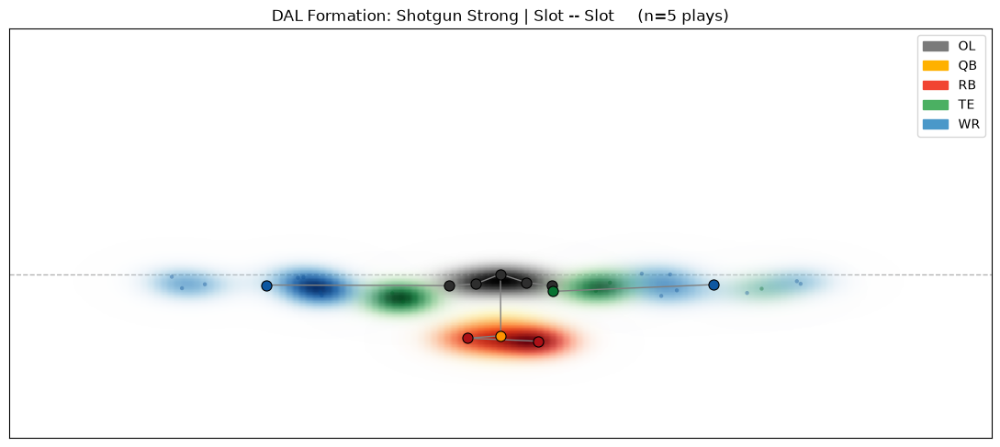

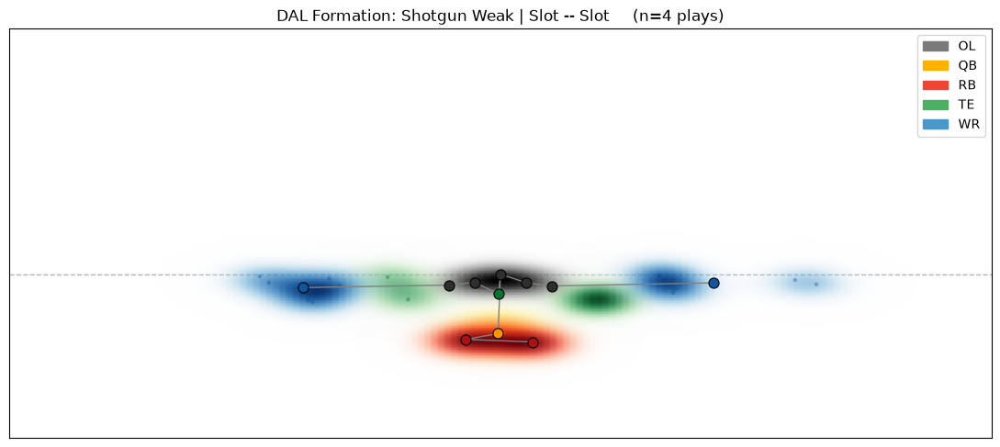

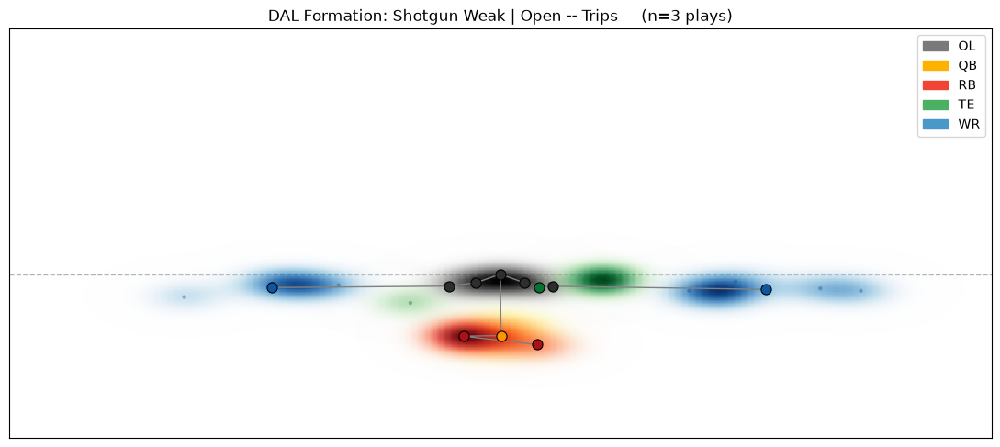

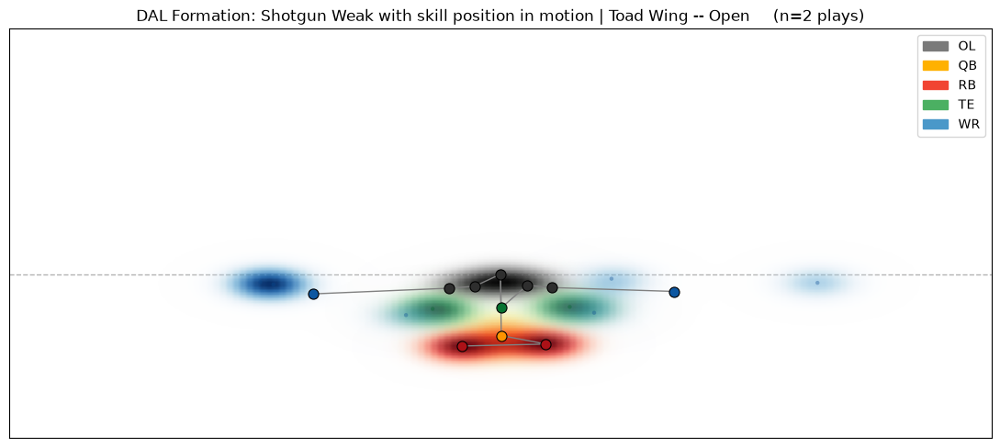

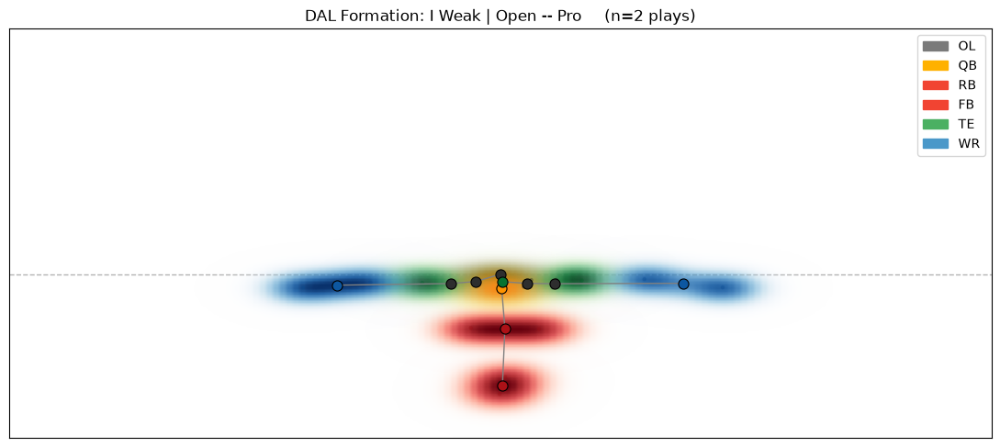

...

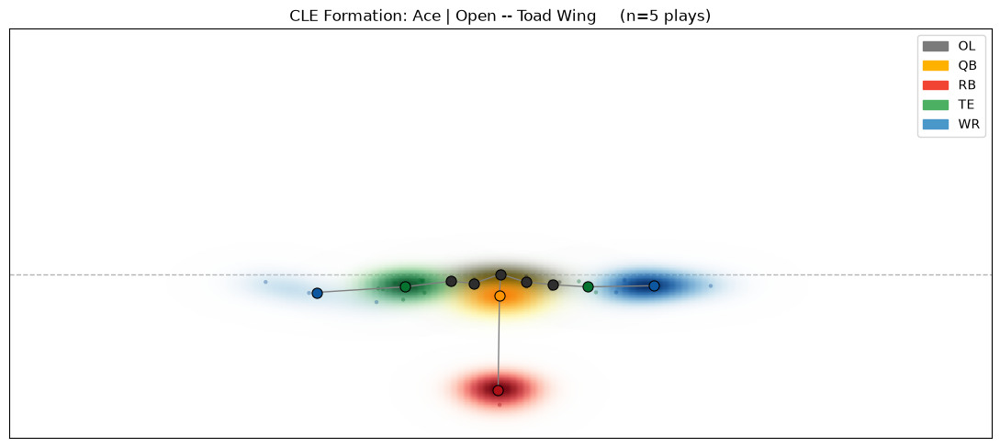

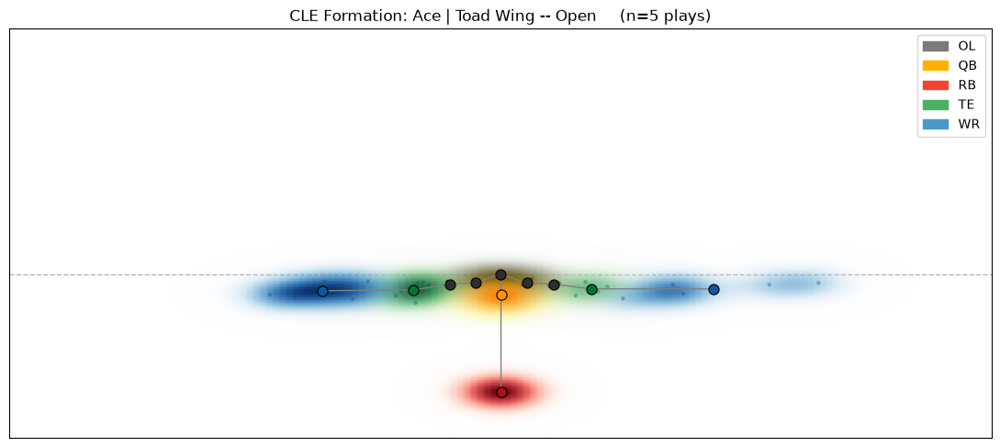

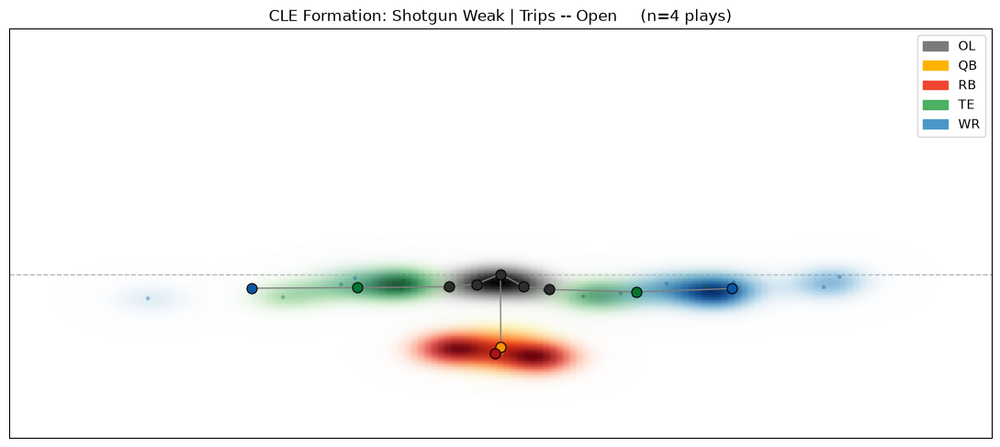

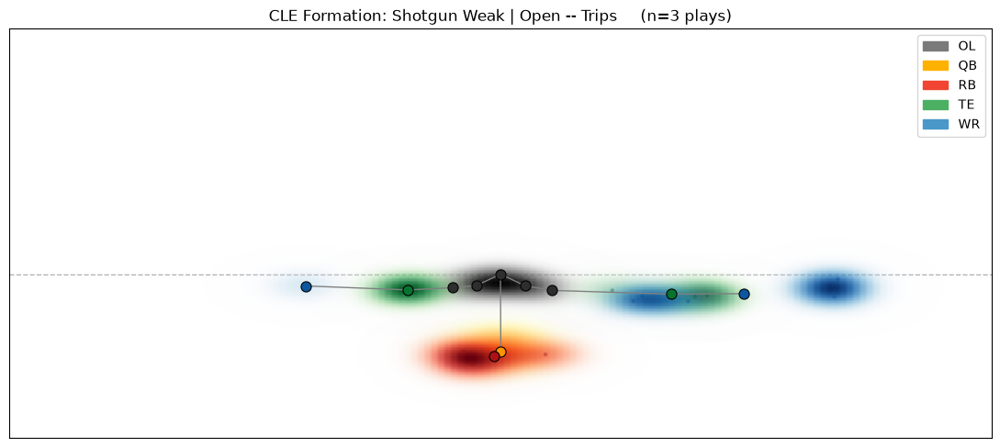

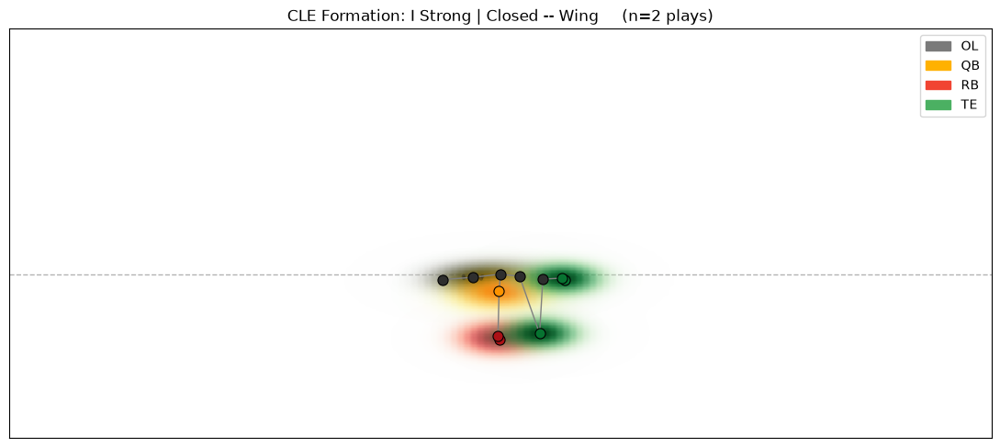

KeyboardInterrupt: 

In [174]:
# plot_top_formations(final_2025_formations, game_id=final_2025_formations['game_id'], team_col= , top_n=3)
unique_games = final_2025_formations[['game_id', 'team_abbr']].drop_duplicates()
# print(unique_games[0])

for _, row in unique_games.iterrows():
    plot_top_formations(final_2025_formations, game_id=row['game_id'], team_col="team_abbr", team=row['team_abbr'], top_n=5)
